# 13_survival_models.ipynb — Survival model เป็นโมเดลเปรียบเทียบ (ขั้นที่ 3 จาก 4)

## ปัญหาของข้อมูล และวิธีแก้
Dataset **ไม่มีวันที่ readmit จริง** มีแค่ 3 ช่วง จึงเป็น *interval-censored data*:

| readmitted | ความหมายเชิงเวลา T (วันจนถึง readmit) |
|---|---|
| `<30` | 0 < T ≤ 30 |
| `>30` | 30 < T ≤ H |
| `NO` | T > H (right-censored) |

H = ระยะติดตามผล ซึ่ง dataset ไม่ได้ระบุ ต้องตั้งเป็นสมมติฐาน (ค่าเริ่มต้น 365 วัน)

## โมเดล 2 ตัว
1. **Grouped-time Cox proportional hazards** (Prentice & Gloeckler, 1978) — Cox model สำหรับเวลาที่ถูกแบ่งเป็นช่วง
   ให้ **hazard ratio (HR)** ที่ตีความได้ และ**ผลการจัดอันดับไม่ขึ้นกับค่า H เลย** (H เปลี่ยนแค่ baseline hazard ไม่เปลี่ยน β) จึงไม่มีปัญหาเรื่องสมมติฐาน H
   เขียน maximum likelihood เองด้วย scipy (ไม่ต้องลง lifelines)
2. **XGBoost AFT** (`objective="survival:aft"`) — survival model แบบ non-linear รองรับ interval censoring โดยตรง ใช้เทียบกับ stacking แบบยุติธรรม (ต้นไม้ vs ต้นไม้) ตัวนี้ขึ้นกับ H จึงทำ sensitivity analysis

## จุดเด่นที่ต้องเขียนในเปเปอร์
โมเดล survival **ตัวเดียว** ให้ทั้ง P(readmit ≤ 30 วัน) และ P(readmit ≤ H) ในขณะที่ classifier ต้องเทรนแยกตาม label → เทียบกับ stacking ของ notebook 11 ได้**ทั้งสอง label** บน test set ชุดเดียวกัน

ต้องการ: `readmission_features.py`, `split_assignment.csv`, `11_any/test_predictions.csv`, `11_30d/test_predictions.csv`, xgboost

## 0. Config + Imports

In [1]:
RANDOM_STATE = 42
RAW_PATH = "../data/diabetic_data.csv"
SPLIT_PATH = "../outputs/split_assignment.csv"
PRED_11 = {"any": "../outputs/11_any/test_predictions.csv", "30d": "../outputs/11_30d/test_predictions.csv"}
OR_PATH_12 = "../outputs/12_features_any/B_odds_ratios.csv"   # ไว้เทียบ HR กับ OR
OUT_DIR = "../outputs/13_survival"

H_DEFAULT = 365                    # ระยะติดตามผลสมมติ (วัน)
H_SENSITIVITY = [180, 365, 730]    # ใช้กับ XGBoost AFT
N_BOOT_HR = 100                    # cluster bootstrap สำหรับ CI ของ HR
N_BOOT_TEST = 300                  # cluster bootstrap สำหรับ CI ของ metric บน test

In [ ]:
import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

from readmission_features import load_prepared, attach_split, add_id_groups, build_lr_design
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("⚠️ ไม่พบ xgboost — ข้ามส่วน XGBoost AFT")

os.makedirs(OUT_DIR, exist_ok=True)

## 1. โหลดข้อมูล + สร้าง outcome แบบช่วงเวลา
`cat` = 0 (`<30`), 1 (`>30`), 2 (`NO`) — เรียงตามเวลาที่เกิดเหตุการณ์ (เร็ว → ไม่เกิด)

In [3]:
X, y_any, groups, meta, readable = load_prepared(RAW_PATH, "any")
split = attach_split(meta, SPLIT_PATH)
cat = meta["readmitted_raw"].map({"<30": 0, ">30": 1, "NO": 2}).values
R = add_id_groups(readable)

idx = {s: np.where(split == s)[0] for s in ["train", "val", "test"]}
D_tr = build_lr_design(R.iloc[idx["train"]])
D = {s: build_lr_design(R.iloc[i], columns=D_tr.columns).values for s, i in idx.items()}
Xs = {s: X.iloc[i].reset_index(drop=True) for s, i in idx.items()}
C = {s: cat[i] for s, i in idx.items()}
G = {s: groups[i] for s, i in idx.items()}

for s in idx:
    counts = np.bincount(C[s], minlength=3) / len(C[s])
    print(f"{s:5s} n={len(C[s]):6,}  <30={counts[0]:.3f}  >30={counts[1]:.3f}  NO={counts[2]:.3f}")

train n=63,605  <30=0.114  >30=0.358  NO=0.528
val   n=15,962  <30=0.113  >30=0.361  NO=0.526
test  n=19,773  <30=0.113  >30=0.352  NO=0.535


## 2. Cumulative incidence แบบไม่ใช้โมเดล (non-parametric)
เมื่อมีแค่ 2 จุดตัด ค่าประมาณแบบ non-parametric คือสัดส่วนสะสม ณ วันที่ 30 และ H ตรงๆ แยกตามกลุ่มสำคัญจาก notebook 12 (เส้นหลังวันที่ 30 เป็นเส้นประ เพราะไม่รู้ว่าเกิดช่วงไหนระหว่าง 30–H)

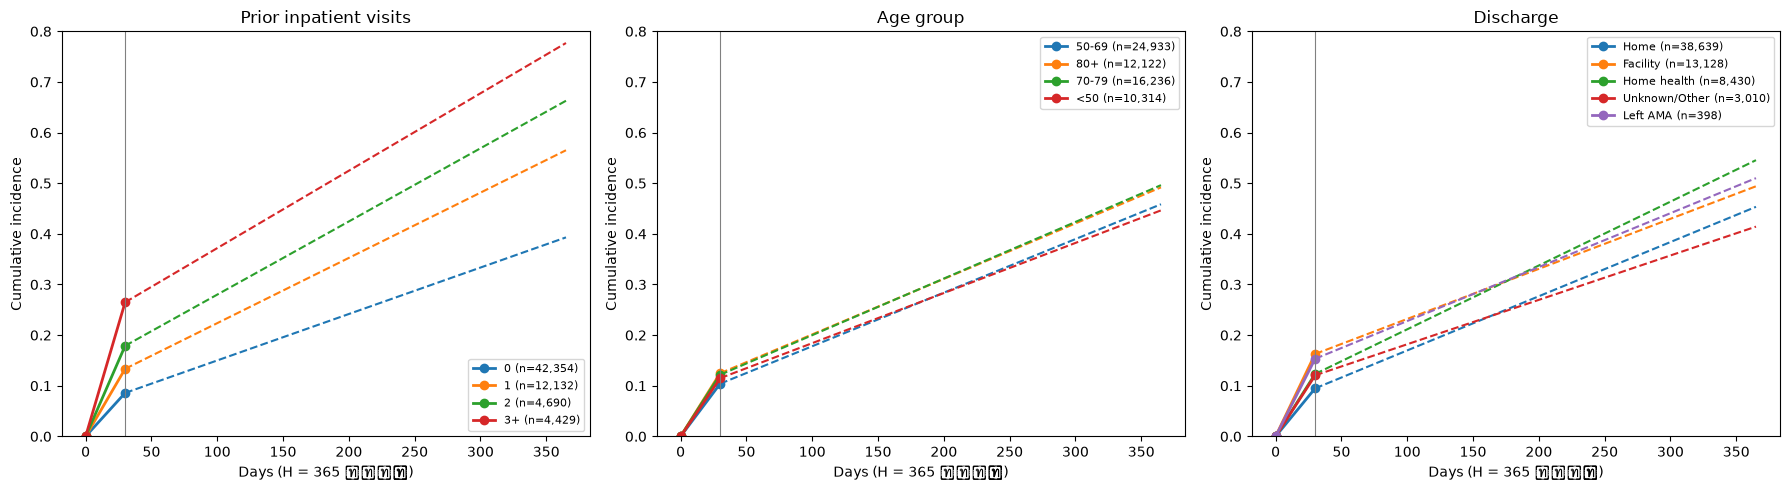

In [4]:
Rtr = R.iloc[idx["train"]].reset_index(drop=True)
ctr = C["train"]
strata = {
    "Prior inpatient visits": pd.cut(Rtr["number_inpatient"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"]),
    "Age group": pd.cut(Rtr["age_ord"], [0, 50, 70, 80, 100], labels=["<50", "50-69", "70-79", "80+"]),
    "Discharge": Rtr["discharge_group"],
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, s) in zip(axes, strata.items()):
    for g in s.dropna().unique():
        m = (s == g).values
        if m.sum() < 200:
            continue
        f30 = (ctr[m] == 0).mean()
        fH = (ctr[m] <= 1).mean()
        ax.plot([0, 30], [0, f30], "-o", lw=2, label=f"{g} (n={m.sum():,})")
        ax.plot([30, H_DEFAULT], [f30, fH], "--", color=ax.lines[-1].get_color())
    ax.axvline(30, c="grey", lw=0.8)
    ax.set_title(title); ax.set_xlabel(f"Days (H = {H_DEFAULT} สมมติ)"); ax.set_ylabel("Cumulative incidence")
    ax.legend(fontsize=8); ax.set_ylim(0, 0.8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/1_cumulative_incidence.png", dpi=150); plt.show()

## 3. Grouped-time Cox Proportional Hazards

Cumulative hazard ณ จุดตัด j: Λⱼ(x) = exp(αⱼ + xβ) โดย α₁ < α₂ (บังคับด้วย α₂ = α₁ + e^δ)

| กลุ่ม | Likelihood |
|---|---|
| `<30` | 1 − exp(−Λ₁) |
| `>30` | exp(−Λ₁) − exp(−Λ₂) |
| `NO` | exp(−Λ₂) |

**HR = exp(β)** ตีความได้เหมือน Cox model ปกติ: HR = 1.5 แปลว่า hazard ของการ readmit สูงกว่า 1.5 เท่า *ในทุกช่วงเวลา* (นี่คือสมมติฐาน proportional hazards ซึ่งทดสอบในหัวข้อ 4)

**ทำไม H ไม่มีผล**: H ปรากฏเฉพาะใน α₂ ซึ่งเป็นพารามิเตอร์อิสระอยู่แล้ว β และอันดับความเสี่ยงจึงเหมือนเดิมทุกค่า H

In [5]:
class GroupedPH:
    """Grouped-time proportional hazards (cloglog cumulative model) — MLE ด้วย L-BFGS + analytic gradient
    cat ∈ {0..J}: 0 = เกิดก่อนจุดตัดแรก, J = ไม่เกิดจนจบการติดตาม (J = จำนวนจุดตัด)"""

    def __init__(self, l2=1e-4):
        self.l2 = l2

    def _unpack(self, w):
        J, p = self.J, self.p
        a1, deltas, beta = w[0], w[1:J], w[J:]
        alphas = a1 + np.concatenate([[0.0], np.cumsum(np.exp(deltas))])
        return alphas, deltas, beta

    def _negll(self, w, Z, c):
        J = self.J
        alphas, deltas, beta = self._unpack(w)
        eta = Z @ beta
        Lam = np.exp(np.clip(alphas[None, :] + eta[:, None], -30, 30))   # n × J
        ll = np.zeros(len(c)); dLam = np.zeros_like(Lam)
        m = c == 0
        ll[m] = np.log(-np.expm1(-Lam[m, 0]))
        dLam[m, 0] = 1.0 / np.expm1(Lam[m, 0])
        for k in range(1, J):
            m = c == k
            Dk = Lam[m, k] - Lam[m, k - 1]
            ll[m] = -Lam[m, k - 1] + np.log(-np.expm1(-Dk))
            dLam[m, k - 1] = -1.0 - 1.0 / np.expm1(Dk)
            dLam[m, k] = 1.0 / np.expm1(Dk)
        m = c == J
        ll[m] = -Lam[m, J - 1]
        dLam[m, J - 1] = -1.0
        dA = (dLam * Lam)                         # ∂ℓ/∂(αⱼ + η)
        g_alpha = dA.sum(axis=0)                  # ∂ℓ/∂αⱼ
        g_beta = Z.T @ dA.sum(axis=1)
        # chain rule: α₁ มีผลกับทุก αⱼ, δₖ มีผลกับ αⱼ ที่ j ≥ k
        g_a1 = g_alpha.sum()
        g_delta = np.array([g_alpha[k:].sum() * np.exp(deltas[k - 1]) for k in range(1, J)])
        n = len(c)
        f = -ll.sum() / n + self.l2 * beta @ beta
        g = -np.concatenate([[g_a1], g_delta, g_beta]) / n
        g[J:] += 2 * self.l2 * beta
        return f, g

    def fit(self, Z, c, n_cuts):
        self.J, self.p = n_cuts, Z.shape[1]
        self.mu_, self.sd_ = Z.mean(0), Z.std(0) + 1e-12
        Zs = (Z - self.mu_) / self.sd_
        w0 = np.zeros(self.J + self.p)
        w0[0] = np.log(-np.log(1 - max((c == 0).mean(), 1e-3)))
        res = minimize(self._negll, w0, args=(Zs, c), jac=True, method="L-BFGS-B",
                       options={"maxiter": 2000})
        self.converged_ = res.success
        alphas, _, beta_s = self._unpack(res.x)
        self.beta_ = beta_s / self.sd_                     # กลับเป็นหน่วยเดิม
        self.alphas_ = alphas - (self.mu_ / self.sd_) @ beta_s
        return self

    def linear_predictor(self, Z):
        return Z @ self.beta_

    def cum_incidence(self, Z):
        """คืน n × J: P(T ≤ จุดตัด j)"""
        Lam = np.exp(np.clip(self.alphas_[None, :] + self.linear_predictor(Z)[:, None], -30, 30))
        return -np.expm1(-Lam)

ph = GroupedPH().fit(D["train"], C["train"], n_cuts=2)
print(f"Converged: {ph.converged_}")
F_val = ph.cum_incidence(D["val"])
print(f"val ROC-AUC  (≤30 วัน): {roc_auc_score(C['val'] == 0, F_val[:, 0]):.4f}")
print(f"val ROC-AUC  (≤H, label any): {roc_auc_score(C['val'] <= 1, F_val[:, 1]):.4f}")

Converged: True
val ROC-AUC  (≤30 วัน): 0.6238
val ROC-AUC  (≤H, label any): 0.6727


In [6]:
# CI ของ HR ด้วย cluster bootstrap ตามผู้ป่วย (เหมือน notebook 12)
rng = np.random.default_rng(RANDOM_STATE)
g_tr = G["train"]
uniq = np.unique(g_tr)
rows_by_patient = pd.Series(np.arange(len(g_tr))).groupby(g_tr).apply(np.array)

boot = []
for b in range(N_BOOT_HR):
    pick = rng.choice(uniq, size=len(uniq), replace=True)
    ii = np.concatenate(rows_by_patient.loc[pick].values)
    boot.append(GroupedPH().fit(D["train"][ii], C["train"][ii], 2).beta_)
    if (b + 1) % 25 == 0:
        print(f"  bootstrap {b+1}/{N_BOOT_HR}")
boot = np.array(boot)

hr = pd.DataFrame({
    "HR": np.exp(ph.beta_),
    "CI_low": np.exp(np.percentile(boot, 2.5, axis=0)),
    "CI_high": np.exp(np.percentile(boot, 97.5, axis=0)),
}, index=D_tr.columns)
hr["significant"] = (hr["CI_low"] > 1) | (hr["CI_high"] < 1)
hr = hr.round(3).sort_values("HR", ascending=False)
hr.to_csv(f"{OUT_DIR}/3_hazard_ratios.csv")
print(hr.to_string())

  bootstrap 25/100
  bootstrap 50/100
  bootstrap 75/100
  bootstrap 100/100
                                           HR  CI_low  CI_high  significant
number_inpatient (per visit, cap 5)     1.288   1.278    1.302         True
admission_type_group = Unknown/Other    1.265   1.194    1.328         True
diabetesMed = Yes                       1.243   1.201    1.292         True
max_glu_serum = >300                    1.166   1.073    1.256         True
number_emergency (per visit, cap 5)     1.129   1.115    1.144         True
discharge_group = Home health           1.101   1.066    1.143         True
admission_type_group = Urgent           1.090   1.047    1.118         True
metformin = Down                        1.082   0.937    1.256        False
discharge_group = Left AMA              1.072   0.904    1.205        False
number_outpatient (per visit, cap 5)    1.064   1.053    1.076         True
number_diagnoses (per 1)                1.048   1.042    1.057         True
age (per 10

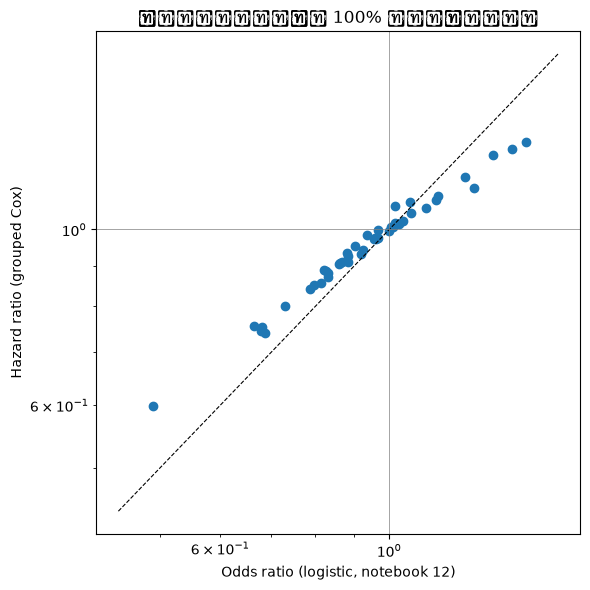

HR มักใกล้ 1 กว่า OR เมื่อ outcome พบบ่อย (~47%) — เป็นเรื่องปกติทางสถิติ ไม่ใช่ความขัดแย้ง


In [7]:
# เทียบ HR (survival) กับ OR (logistic, notebook 12) — ทิศทางควรตรงกัน
if os.path.exists(OR_PATH_12):
    orr = pd.read_csv(OR_PATH_12, index_col=0)
    both = hr[["HR"]].join(orr[["OR"]], how="inner")
    same_dir = (np.sign(np.log(both["HR"])) == np.sign(np.log(both["OR"]))).mean()
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(both["OR"], both["HR"])
    lim = [min(both.min()) * 0.9, max(both.max()) * 1.1]
    ax.plot(lim, lim, "k--", lw=0.8); ax.axhline(1, c="grey", lw=0.5); ax.axvline(1, c="grey", lw=0.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Odds ratio (logistic, notebook 12)"); ax.set_ylabel("Hazard ratio (grouped Cox)")
    ax.set_title(f"ทิศทางตรงกัน {same_dir*100:.0f}% ของตัวแปร")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/3_hr_vs_or.png", dpi=150); plt.show()
    print("HR มักใกล้ 1 กว่า OR เมื่อ outcome พบบ่อย (~47%) — เป็นเรื่องปกติทางสถิติ ไม่ใช่ความขัดแย้ง")
else:
    print("ไม่พบผลจาก notebook 12 — ข้ามการเทียบ")

## 4. ทดสอบสมมติฐาน Proportional Hazards

ถ้าสมมติฐานเป็นจริง ผลของตัวแปรต่อ "readmit ภายใน 30 วัน" และ "readmit ภายใน H" ต้องเท่ากัน
ทดสอบโดยเทรน cloglog แยก 2 ตัว (จุดตัดเดียว) แล้วเทียบ log-HR — จุดที่ห่างจากเส้นทแยงมากคือตัวแปรที่ **ผลเปลี่ยนตามเวลา** (มีประโยชน์ในเชิงความเข้าใจโรคด้วย เช่น ปัจจัยที่สำคัญเฉพาะช่วงแรกหลังจำหน่าย)

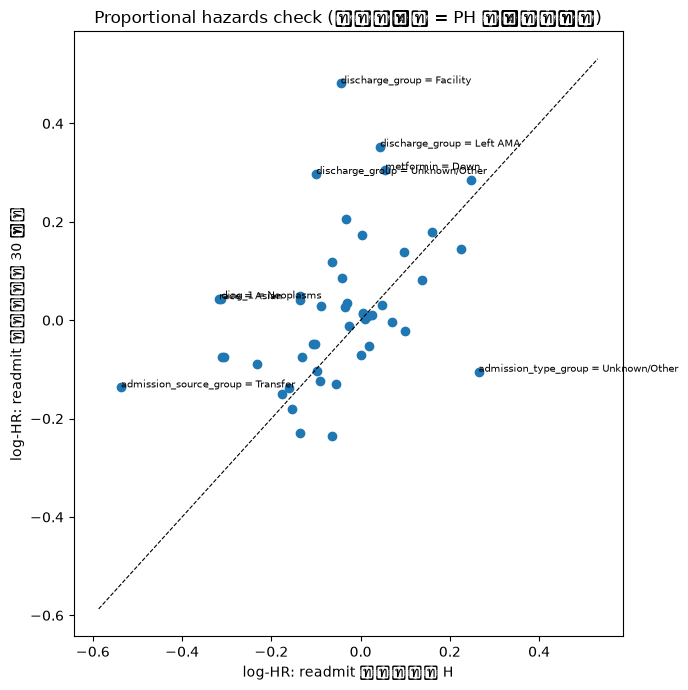

ตัวแปรที่ผลต่างกันมากที่สุดระหว่างสองช่วงเวลา:
                                      HR_30d   HR_H  ratio_30d_over_H
admission_type_group = Unknown/Other   0.901  1.302             0.691
diag_1 = Respiratory                   0.790  0.939             0.842
admission_type_group = Urgent          0.979  1.104             0.887
metformin = Up                         0.795  0.873             0.910
diabetesMed = Yes                      1.156  1.252             0.923
diag_1 = Neoplasms                     1.045  0.732             1.427
race = Asian                           1.044  0.728             1.433
discharge_group = Unknown/Other        1.346  0.905             1.487
admission_source_group = Transfer      0.872  0.585             1.492
discharge_group = Facility             1.618  0.957             1.692

Spearman corr ของ log-HR สองช่วง: 0.429


In [8]:
c30 = np.where(C["train"] == 0, 0, 1)        # เหตุการณ์ภายใน 30 วัน vs ไม่
cH = np.where(C["train"] <= 1, 0, 1)         # เหตุการณ์ภายใน H vs ไม่
b30 = GroupedPH().fit(D["train"], c30, 1).beta_
bH = GroupedPH().fit(D["train"], cH, 1).beta_

ph_check = pd.DataFrame({"HR_30d": np.exp(b30), "HR_H": np.exp(bH)}, index=D_tr.columns)
ph_check["ratio_30d_over_H"] = ph_check["HR_30d"] / ph_check["HR_H"]
ph_check = ph_check.round(3).sort_values("ratio_30d_over_H")
ph_check.to_csv(f"{OUT_DIR}/4_ph_check.csv")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(bH, b30)
lim = [min(bH.min(), b30.min()) - 0.05, max(bH.max(), b30.max()) + 0.05]
ax.plot(lim, lim, "k--", lw=0.8)
far = np.argsort(-np.abs(b30 - bH))[:8]
for i in far:
    ax.annotate(D_tr.columns[i], (bH[i], b30[i]), fontsize=7)
ax.set_xlabel("log-HR: readmit ภายใน H"); ax.set_ylabel("log-HR: readmit ภายใน 30 วัน")
ax.set_title("Proportional hazards check (บนเส้น = PH เป็นจริง)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/4_ph_check.png", dpi=150); plt.show()

print("ตัวแปรที่ผลต่างกันมากที่สุดระหว่างสองช่วงเวลา:")
print(ph_check.iloc[list(range(5)) + list(range(-5, 0))].to_string())
print(f"\nSpearman corr ของ log-HR สองช่วง: {pd.Series(b30).corr(pd.Series(bH), method='spearman'):.3f}")

## 5. XGBoost AFT (non-linear survival)

- ใช้ feature ชุดเดียวกับ stacking (54 ตัว encoded) → เทียบได้ตรงๆ
- `aft_loss_distribution="extreme"` = Weibull AFT (เข้าคู่กับ Cox model)
- เลือก `aft_loss_distribution_scale` (σ) และจำนวนต้นไม้ด้วย validation set
- ทำซ้ำหลายค่า H เพื่อดูว่าผลไวต่อสมมติฐานนี้แค่ไหน

In [9]:
def aft_bounds(c, H):
    lo = np.select([c == 0, c == 1, c == 2], [0.0, 30.0, float(H)])
    hi = np.select([c == 0, c == 1, c == 2], [30.0, float(H), np.inf])
    return lo, hi

def make_dmatrix(Xd, c, H):
    d = xgb.DMatrix(Xd)
    lo, hi = aft_bounds(c, H)
    d.set_float_info("label_lower_bound", lo)
    d.set_float_info("label_upper_bound", hi)
    return d

def aft_cdf(pred_time, t, sigma):
    """P(T ≤ t) ภายใต้ log T = μ + σ·Z, Z ~ extreme value (min) → Weibull"""
    z = (np.log(t) - np.log(pred_time)) / sigma
    return -np.expm1(-np.exp(np.clip(z, -30, 30)))

aft_models = {}
if HAS_XGB:
    for H in H_SENSITIVITY:
        dtr = make_dmatrix(Xs["train"], C["train"], H)
        dva = make_dmatrix(Xs["val"], C["val"], H)
        best = None
        for sigma in [0.5, 1.0, 1.5, 2.0]:
            params = {"objective": "survival:aft", "eval_metric": "aft-nloglik",
                      "aft_loss_distribution": "extreme", "aft_loss_distribution_scale": sigma,
                      "tree_method": "hist", "learning_rate": 0.03, "max_depth": 4,
                      "subsample": 0.9, "min_child_weight": 5, "seed": RANDOM_STATE}
            bst = xgb.train(params, dtr, num_boost_round=3000, evals=[(dva, "val")],
                            early_stopping_rounds=100, verbose_eval=False)
            if best is None or bst.best_score < best[0]:
                best = (bst.best_score, sigma, bst)
        score, sigma, bst = best
        aft_models[H] = {"booster": bst, "sigma": sigma}
        pv = bst.predict(xgb.DMatrix(Xs["val"]), iteration_range=(0, bst.best_iteration + 1))
        print(f"H={H:4d}: σ={sigma}, trees={bst.best_iteration + 1}, val nloglik={score:.4f}, "
              f"val ROC-AUC(any)={roc_auc_score(C['val'] <= 1, -np.log(pv)):.4f}")

H= 180: σ=1.0, trees=1110, val nloglik=0.8914, val ROC-AUC(any)=0.6927
H= 365: σ=1.5, trees=1155, val nloglik=0.8922, val ROC-AUC(any)=0.6921
H= 730: σ=2.0, trees=1122, val nloglik=0.8928, val ROC-AUC(any)=0.6930


## 6. เทียบกับ Stacking บน Test Set (ผู้ป่วยชุดเดียวกับ notebook 11)

วัด 3 อย่าง:
- **ROC-AUC / PR-AUC สำหรับ label `any`** — survival ใช้ P(T ≤ H)
- **ROC-AUC / PR-AUC สำหรับ label `30d`** — survival ใช้ P(T ≤ 30)
- **Ordinal C-index** — วัดว่าโมเดลเรียงลำดับ `<30` > `>30` > `NO` ได้ถูกแค่ไหน (เป็น C-index ของ survival ที่ใช้กับข้อมูล 3 ช่วงนี้ได้)

CI 95% จาก cluster bootstrap ตามผู้ป่วยบน test และรายงาน **ผลต่างแบบ paired** เทียบกับ stacking (label any)

In [10]:
def ordinal_cindex(c, risk):
    num = den = 0.0
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        m = (c == a) | (c == b)
        na, nb = (c == a).sum(), (c == b).sum()
        if na and nb:
            num += na * nb * roc_auc_score(c[m] == a, risk[m])
            den += na * nb
    return num / den

test_meta = meta.iloc[idx["test"]][["encounter_id"]].reset_index(drop=True)
c_te = C["test"]
scores = {}   # ชื่อโมเดล → (score สำหรับ any, score สำหรับ 30d, risk สำหรับ C-index)

for lab, path in PRED_11.items():
    p = test_meta.merge(pd.read_csv(path)[["encounter_id", "proba_calibrated"]], on="encounter_id", how="left")
    assert p["proba_calibrated"].notna().all(), f"test set ไม่ตรงกับ {path}"
    v = p["proba_calibrated"].values
    scores[f"Stacking (trained on {lab})"] = (v, v, v)

F_te = ph.cum_incidence(D["test"])
scores["Grouped Cox PH"] = (F_te[:, 1], F_te[:, 0], ph.linear_predictor(D["test"]))

for H, m in aft_models.items():
    bst = m["booster"]
    pt = bst.predict(xgb.DMatrix(Xs["test"]), iteration_range=(0, bst.best_iteration + 1))
    scores[f"XGBoost AFT (H={H})"] = (aft_cdf(pt, H, m["sigma"]), aft_cdf(pt, 30, m["sigma"]), -np.log(pt))

y_any_te, y_30_te = (c_te <= 1).astype(int), (c_te == 0).astype(int)

def all_metrics(sa, s30, r, ii=None):
    ii = slice(None) if ii is None else ii
    return {
        "ROC_AUC_any": roc_auc_score(y_any_te[ii], sa[ii]),
        "PR_AUC_any": average_precision_score(y_any_te[ii], sa[ii]),
        "ROC_AUC_30d": roc_auc_score(y_30_te[ii], s30[ii]),
        "PR_AUC_30d": average_precision_score(y_30_te[ii], s30[ii]),
        "C_index": ordinal_cindex(c_te[ii], r[ii]),
    }

point = pd.DataFrame({k: all_metrics(*v) for k, v in scores.items()}).T
print(f"Base rate test: any={y_any_te.mean():.4f}, 30d={y_30_te.mean():.4f}\n")
print(point.round(4).to_string())

Base rate test: any=0.4651, 30d=0.1135

                           ROC_AUC_any  PR_AUC_any  ROC_AUC_30d  PR_AUC_30d  C_index
Stacking (trained on any)       0.6806      0.6365       0.6447      0.1999   0.6625
Stacking (trained on 30d)       0.6459      0.6006       0.6745      0.2146   0.6405
Grouped Cox PH                  0.6729      0.6376       0.6320      0.1967   0.6546
XGBoost AFT (H=180)             0.6936      0.6579       0.6544      0.2152   0.6742
XGBoost AFT (H=365)             0.6937      0.6585       0.6548      0.2179   0.6744
XGBoost AFT (H=730)             0.6942      0.6589       0.6553      0.2180   0.6748


In [11]:
# Cluster bootstrap บน test: CI ของแต่ละ metric + ผลต่าง paired เทียบกับ stacking (any)
g_te = G["test"]
uniq_te = np.unique(g_te)
rows_te = pd.Series(np.arange(len(g_te))).groupby(g_te).apply(np.array)
ref = "Stacking (trained on any)"
rng = np.random.default_rng(RANDOM_STATE)

boot_rows = []
for b in range(N_BOOT_TEST):
    ii = np.concatenate(rows_te.loc[rng.choice(uniq_te, len(uniq_te), replace=True)].values)
    res = {k: all_metrics(*v, ii=ii) for k, v in scores.items()}
    for k in scores:
        for met, val in res[k].items():
            boot_rows.append({"model": k, "metric": met, "value": val, "delta": val - res[ref][met], "b": b})
bt = pd.DataFrame(boot_rows)

summ = bt.groupby(["model", "metric"]).agg(
    lo=("value", lambda s: s.quantile(0.025)), hi=("value", lambda s: s.quantile(0.975)),
    d_lo=("delta", lambda s: s.quantile(0.025)), d_hi=("delta", lambda s: s.quantile(0.975)),
).reset_index()
summ["point"] = [point.loc[m, met] for m, met in zip(summ["model"], summ["metric"])]
summ["95% CI"] = summ.apply(lambda r: f"{r.point:.4f} ({r.lo:.4f}–{r.hi:.4f})", axis=1)
summ["Δ vs stacking(any)"] = summ.apply(
    lambda r: "—" if r.model == ref else
    f"{r.point - point.loc[ref, r.metric]:+.4f} ({r.d_lo:+.4f}, {r.d_hi:+.4f})" +
    (" *" if (r.d_lo > 0 or r.d_hi < 0) else ""), axis=1)

table = summ.pivot(index="model", columns="metric", values="95% CI")
delta = summ.pivot(index="model", columns="metric", values="Δ vs stacking(any)")
table.to_csv(f"{OUT_DIR}/6_test_comparison_ci.csv"); delta.to_csv(f"{OUT_DIR}/6_test_delta_vs_stacking.csv")
print("Metric + 95% CI:\n", table.to_string())
print("\nผลต่างจาก stacking (any) + 95% CI  (* = ต่างอย่างมีนัยสำคัญ):\n", delta.to_string())

Metric + 95% CI:
 metric                                    C_index              PR_AUC_30d              PR_AUC_any             ROC_AUC_30d             ROC_AUC_any
model                                                                                                                                            
Grouped Cox PH             0.6546 (0.6459–0.6624)  0.1967 (0.1790–0.2167)  0.6376 (0.6220–0.6515)  0.6320 (0.6172–0.6454)  0.6729 (0.6632–0.6811)
Stacking (trained on 30d)  0.6405 (0.6315–0.6493)  0.2146 (0.1933–0.2361)  0.6006 (0.5869–0.6145)  0.6745 (0.6602–0.6875)  0.6459 (0.6365–0.6556)
Stacking (trained on any)  0.6625 (0.6538–0.6699)  0.1999 (0.1782–0.2238)  0.6365 (0.6223–0.6488)  0.6447 (0.6285–0.6585)  0.6806 (0.6718–0.6882)
XGBoost AFT (H=180)        0.6742 (0.6661–0.6823)  0.2152 (0.1926–0.2402)  0.6579 (0.6424–0.6699)  0.6544 (0.6394–0.6682)  0.6936 (0.6848–0.7019)
XGBoost AFT (H=365)        0.6744 (0.6662–0.6824)  0.2179 (0.1949–0.2430)  0.6585 (0.6431–0.6707)  0.6548 

## 7. Calibration ของความน่าจะเป็นจาก survival model
Survival model ให้ความน่าจะเป็นโดยไม่ต้อง calibrate แยก ลองดูว่าตรงกับความจริงแค่ไหนทั้งสองช่วงเวลา (P(T≤H) ของ AFT ขึ้นกับ H ที่สมมติ จึงดูที่ H=365 เป็นหลัก)

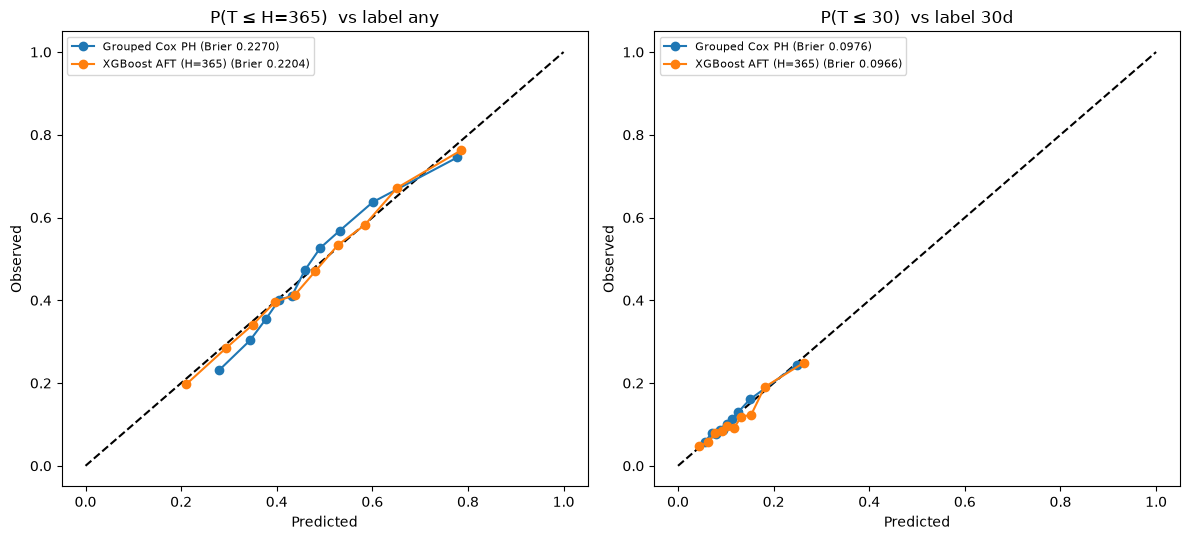

In [12]:
from sklearn.calibration import calibration_curve
show = [k for k in scores if not k.startswith("Stacking")]
show = [k for k in show if "AFT" not in k or f"H={H_DEFAULT})" in k]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (j, ytrue, title) in zip(axes, [(1, y_any_te, f"P(T ≤ H={H_DEFAULT})  vs label any"),
                                        (0, y_30_te, "P(T ≤ 30)  vs label 30d")]):
    ax.plot([0, 1], [0, 1], "k--")
    for k in show:
        pr = scores[k][0] if j == 1 else scores[k][1]
        fp, mp = calibration_curve(ytrue, pr, n_bins=10, strategy="quantile")
        ax.plot(mp, fp, "o-", label=f"{k} (Brier {brier_score_loss(ytrue, pr):.4f})")
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("Observed"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/7_calibration.png", dpi=150); plt.show()

## 8. บันทึกผล + แนวทางเขียนเปเปอร์

**สิ่งที่รายงาน**
- ตาราง 6 (metric + CI และ Δ เทียบ stacking) เป็นตารางหลักของส่วน model comparison
- ตาราง HR (หัวข้อ 3) คู่กับ OR ของ notebook 12 → ปัจจัยเสี่ยงยืนยันกันจาก 2 กรอบวิธี
- ผล PH check (หัวข้อ 4) → ตัวแปรไหนสำคัญเฉพาะช่วงแรก (≤30 วัน) กับช่วงยาว

**ข้อจำกัดที่ต้องเขียน**
1. ข้อมูลมีจุดตัดเวลาแค่ 2 จุด survival model จึงใช้ศักยภาพได้ไม่เต็มที่ (ไม่มีข้อมูลรูปทรงของ hazard ระหว่างช่วง)
2. H ไม่ระบุใน dataset — Cox แบบ grouped ไม่ได้รับผล แต่ AFT ได้รับผล (ดู sensitivity)
3. Survival model หนึ่งตัวให้ **อันดับความเสี่ยงเดียวกัน** ทั้ง 30 วันและ H (ภายใต้ proportional hazards/AFT) ต่างจาก classifier ที่เทรนแยกได้อันดับต่างกัน

In [13]:
with open(f"{OUT_DIR}/summary.json", "w") as f:
    json.dump({
        "H_default": H_DEFAULT,
        "point_metrics": point.round(4).to_dict(orient="index"),
        "aft_sigma": {int(H): m["sigma"] for H, m in aft_models.items()},
        "grouped_ph_converged": bool(ph.converged_),
    }, f, indent=2, ensure_ascii=False)
print(f"บันทึกผลไว้ที่ {OUT_DIR}/")

บันทึกผลไว้ที่ ../outputs/13_survival/
